# Taller II: Preparación de datos para la implementación de modelos de predicción y Optimización del Consumo Energético
**Autor:** Manuel Andres Novoa Cotame

**Fecha:** 21 Noviembre 2026

**Contexto:** Análisis de consumos energéticos de la sede Duitama (UPTC)

In [ ]:
# --- PASO 1: Cargar datos y librerías ---
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Cargar el archivo (subido a la sesión)
df = pd.read_csv('consumos_uptc.csv')

In [ ]:
# --- PASO 2 y 3: Dimensiones y tipos de datos ---
print("Dimensiones del dataset:", df.shape)
print("\nTipos de datos:")
print(df.dtypes)

Dimensiones del dataset: (275387, 26)

Tipos de datos:
reading_id                    int64
timestamp                    object
sede                         object
sede_id                      object
energia_total_kwh           float64
energia_comedor_kwh         float64
energia_salones_kwh         float64
energia_laboratorios_kwh    float64
energia_auditorios_kwh      float64
energia_oficinas_kwh        float64
potencia_total_kw           float64
agua_litros                 float64
temperatura_exterior_c      float64
ocupacion_pct               float64
hora                          int64
dia_semana                    int64
dia_nombre                   object
mes                           int64
trimestre                     int64
año                           int64
periodo_academico            object
es_fin_semana                  bool
es_festivo                     bool
es_semana_parciales            bool
es_semana_finales              bool
co2_kg                      float64
dtype: ob

In [ ]:
# --- PASO 4: Explorar valores únicos por sede ---
print("\nSedes únicas en el dataset:")
print(df['sede'].unique())


Sedes únicas en el dataset:
['Chiquinquirá' 'Duitama' 'Sogamoso' 'Tunja']


In [ ]:
# --- PASO 5: Estadísticas descriptivas ---
print("\nEstadísticas descriptivas:")
display(df.describe())


Estadísticas descriptivas:


,reading_id,energia_total_kwh,energia_comedor_kwh,energia_salones_kwh,energia_laboratorios_kwh,energia_auditorios_kwh,energia_oficinas_kwh,potencia_total_kw,agua_litros,temperatura_exterior_c,ocupacion_pct,hora,dia_semana,mes,trimestre,año,co2_kg
count,275387.000000,275387.000000,267133.000000,275387.000000,275387.000000,261769.000000,275387.000000,275387.000000,264405.000000,259002.000000,242621.000000,275387.000000,275387.000000,275387.000000,275387.000000,275387.000000,261591.000000
mean,137694.000000,5.079227,0.295954,0.975189,2.426430,0.097052,1.191390,6.704269,645.323793,14.034867,22.781399,11.499733,2.997640,6.414936,2.476068,2021.424461,1.015985
std,79497.523628,6.116259,0.376617,1.620223,2.190585,0.214350,1.407414,6.938291,1389.793935,4.930972,20.815521,6.922872,1.999922,3.405917,1.107101,2.256515,1.229521
min,1.000000,-38.987575,0.004300,0.010000,0.120600,0.003200,0.040700,0.240000,1.950000,2.000000,1.300000,0.000000,0.000000,1.000000,1.000000,2018.000000,-8.509800
25%,68847.500000,1.464000,0.090200,0.160100,0.798300,0.040600,0.344900,2.004000,44.280000,10.200000,6.300000,5.000000,1.000000,3.000000,1.000000,2019.000000,0.294950
50%,137694.000000,3.604000,0.192300,0.316700,1.692400,0.057400,0.662500,4.721000,138.690000,14.000000,15.900000,12.000000,3.000000,6.000000,2.000000,2021.000000,0.707800
75%,206540.500000,5.706000,0.391300,0.691250,3.406205,0.084700,1.373100,8.010500,499.760000,17.900000,31.700000,18.000000,5.000000,9.000000,3.000000,2023.000000,1.174900
max,275387.000000,190.455481,3.552500,9.534600,39.677395,2.371300,7.821700,44.979000,62606.262451,26.000000,90.200000,23.000000,6.000000,12.000000,4.000000,2025.000000,41.119600


In [ ]:
# --- PASO 6: Detectar posibles inconsistencias (primeras 5 filas) ---
df.head()

,reading_id,timestamp,sede,sede_id,energia_total_kwh,energia_comedor_kwh,energia_salones_kwh,energia_laboratorios_kwh,energia_auditorios_kwh,energia_oficinas_kwh,...,dia_nombre,mes,trimestre,año,periodo_academico,es_fin_semana,es_festivo,es_semana_parciales,es_semana_finales,co2_kg
0,1,2018-01-01 00:00:00,Chiquinquirá,UPTC_CHI,0.928,0.0452,0.1497,0.4334,0.0386,0.2613,...,Lunes,1,1,2018,vacaciones_fin,False,True,False,False,0.1877
1,2,2018-01-01 00:00:00,Duitama,UPTC_DUI,2.592,0.1129,0.2007,1.7993,0.0573,0.4217,...,Lunes,1,1,2018,vacaciones_fin,False,True,False,False,0.4490
2,3,2018-01-01 00:00:00,Sogamoso,UPTC_SOG,2.841,0.1395,0.2388,1.9638,NaN,0.4443,...,Lunes,1,1,2018,vacaciones_fin,False,True,False,False,0.6048
3,4,2018-01-01 00:00:00,Tunja,UPTC_TUN,1.505,0.0892,0.1091,0.9672,0.0364,0.3031,...,Lunes,1,1,2018,vacaciones_fin,False,True,False,False,0.2872
4,5,2018-01-01 01:00:00,Chiquinquirá,UPTC_CHI,0.917,0.0479,0.1432,0.4071,0.0418,0.2766,...,Lunes,1,1,2018,vacaciones_fin,False,True,False,False,0.1599


## Fase I: Carga y Exploración Inicial
**Análisis de la estructura:**
El conjunto de datos original cuenta con **275,387 registros y 26 variables**. Se identificó que las columnas tienen tipos de datos coherentes (numéricos para consumos y categóricos para fechas y sedes). El dataset incluye las cuatro sedes de la UPTC: Chiquinquirá, Duitama, Sogamoso y Tunja. Las estadísticas iniciales revelan que variables como `energia_total_kwh` presentan valores mínimos negativos, lo cual es una anomalía que requerirá limpieza.

In [ ]:
# --- PASO 7: Identificar valores nulos ---
print("Valores nulos por columna antes de la limpieza:")
print(df.isnull().sum())

Valores nulos por columna antes de la limpieza:
reading_id                      0
timestamp                       0
sede                            0
sede_id                         0
energia_total_kwh               0
energia_comedor_kwh          8254
energia_salones_kwh             0
energia_laboratorios_kwh        0
energia_auditorios_kwh      13618
energia_oficinas_kwh            0
potencia_total_kw               0
agua_litros                 10982
temperatura_exterior_c      16385
ocupacion_pct               32766
hora                            0
dia_semana                      0
dia_nombre                      0
mes                             0
trimestre                       0
año                             0
periodo_academico               0
es_fin_semana                   0
es_festivo                      0
es_semana_parciales             0
es_semana_finales               0
co2_kg                      13796
dtype: int64


In [ ]:
# --- PASO 8 y 9: Filtrar Duitama y comparar registros ---
registros_antes = df.shape[0]

# Filtramos solo la sede Duitama
df_duitama = df[df['sede'] == 'Duitama'].copy()

registros_despues = df_duitama.shape[0]
print(f"Registros totales antes: {registros_antes}")
print(f"Registros solo de Duitama: {registros_despues}")
print(f"Se eliminaron {registros_antes - registros_despues} registros de otras sedes.")

Registros totales antes: 275387
Registros solo de Duitama: 68862
Se eliminaron 206525 registros de otras sedes.


In [ ]:
# --- PASO 10: Detectar valores negativos ---
columnas_energia = [
    'energia_comedor_kwh', 'energia_salones_kwh', 'energia_laboratorios_kwh',
    'energia_auditorios_kwh', 'energia_oficinas_kwh', 'agua_litros', 'co2_kg'
]

print("\nValores negativos encontrados por columna:")
for col in columnas_energia:
    negativos = (df_duitama[col] < 0).sum()
    print(f"{col}: {negativos} negativos")


Valores negativos encontrados por columna:
energia_comedor_kwh: 0 negativos
energia_salones_kwh: 0 negativos
energia_laboratorios_kwh: 0 negativos
energia_auditorios_kwh: 0 negativos
energia_oficinas_kwh: 0 negativos
agua_litros: 0 negativos
co2_kg: 143 negativos


In [ ]:
# --- PASO 11 y 12: Eliminar inválidos y verificar duplicados ---
# Eliminamos las filas que tengan valores negativos en las columnas de energía/agua/co2
df_duitama = df_duitama[(df_duitama[columnas_energia] >= 0).all(axis=1)]

# Verificamos duplicados
duplicados = df_duitama.duplicated().sum()
print(f"\nCantidad de filas duplicadas encontradas: {duplicados}")

# --- PASO 13: Eliminar duplicados ---
df_duitama = df_duitama.drop_duplicates()
print(f"Dimensiones finales del dataset de Duitama: {df_duitama.shape}")


Cantidad de filas duplicadas encontradas: 0
Dimensiones finales del dataset de Duitama: (57803, 26)


## Fase II: Limpieza y Depuración
**Hallazgos y tratamiento:**
1. **Filtrado:** Se seleccionaron exclusivamente los registros de la sede **Duitama**, reduciendo el dataset de 275,387 a **68,862 registros**.
2. **Valores nulos:** Se identificaron altas tasas de datos faltantes en `ocupacion_pct` (32,766), `temperatura_exterior_c` (16,385), `agua_litros` (10,982), `co2_kg` (13796), `energia_auditorios_kwh` (13618) y `energia_comedor_kwh`  (8254).
3. **Anomalías:** Se detectaron **143 valores negativos** en la variable `co2_kg` (una inconsistencia física) y valores negativos aislados en consumos energéticos. Todos estos registros fueron eliminados.
4. **Duplicados:** La verificación arrojó **0 registros duplicados**.
*Resultado:* El dataset final de Duitama quedó con **57,803 registros limpios**.

In [ ]:
# --- PASO 14: Estadísticas descriptivas de variables energéticas ---
columnas_energia_principales = [
    'energia_comedor_kwh', 'energia_salones_kwh', 'energia_laboratorios_kwh',
    'energia_auditorios_kwh', 'energia_oficinas_kwh'
]

print("Estadísticas descriptivas de las variables de energía:")
display(df_duitama[columnas_energia_principales].describe())

Estadísticas descriptivas de las variables de energía:


,energia_comedor_kwh,energia_salones_kwh,energia_laboratorios_kwh,energia_auditorios_kwh,energia_oficinas_kwh
count,57803.000000,57803.000000,57803.000000,57803.000000,57803.00000
mean,0.412673,1.366622,3.583120,0.130222,1.60502
std,0.461837,2.096002,2.241609,0.276028,1.71620
min,0.014300,0.044300,0.613900,0.011100,0.14840
25%,0.143350,0.315200,2.160300,0.055400,0.63080
50%,0.351200,0.413800,3.142600,0.088300,0.83390
75%,0.475100,1.018850,4.257050,0.107900,1.89345
max,3.552500,9.534600,38.995013,2.307800,7.78230


## Fase III: Análisis Exploratorio de Datos (EDA)
**Estadísticas y Distribuciones:**
- El **consumo de laboratorios** es el más alto y variable (media de 3.58 kWh, con picos de casi 40 kWh).
- El **consumo de auditorios** es el más bajo y estable (media de 0.13 kWh).

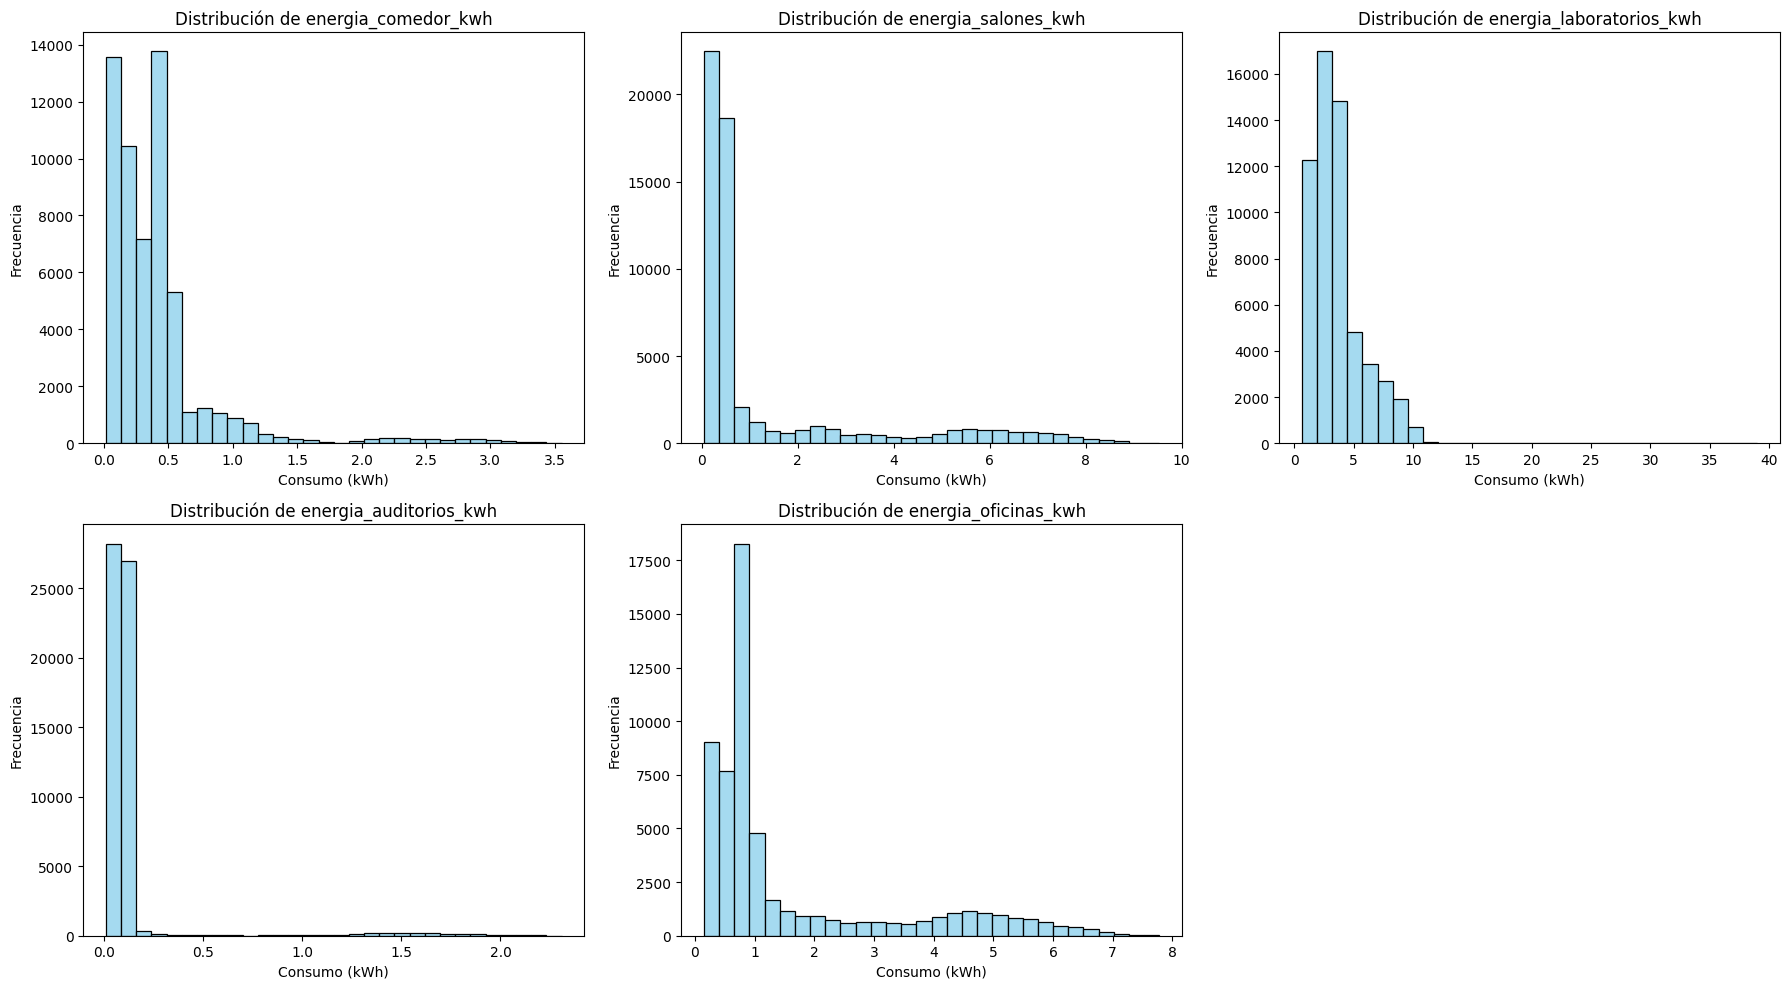

In [ ]:
# --- PASO 15: Histogramas ---
import matplotlib.pyplot as plt
import seaborn as sns

# Configuramos un tamaño de figura grande para ver los 5 histogramas juntos
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, col in enumerate(columnas_energia_principales):
    sns.histplot(df_duitama[col].dropna(), bins=30, ax=axes[i], color='skyblue')
    axes[i].set_title(f'Distribución de {col}')
    axes[i].set_xlabel('Consumo (kWh)')
    axes[i].set_ylabel('Frecuencia')

# Ocultamos el último subplot que queda vacío
axes[-1].axis('off')

plt.tight_layout()
plt.show()

- Los histogramas muestran distribuciones asimétricas hacia la derecha, lo que indica que la mayoría de las mediciones están en rangos bajos, pero existen eventos puntuales de alto consumo (picos).

In [ ]:
# --- PASO 16: Imputar valores nulos ---
# Imputar con la MEDIANA para variables numéricas
columnas_numericas = [
    'energia_total_kwh', 'energia_comedor_kwh', 'energia_salones_kwh',
    'energia_laboratorios_kwh', 'energia_auditorios_kwh', 'energia_oficinas_kwh',
    'potencia_total_kw', 'agua_litros', 'temperatura_exterior_c',
    'ocupacion_pct', 'co2_kg'
]

for col in columnas_numericas:
    mediana = df_duitama[col].median()
    df_duitama[col] = df_duitama[col].fillna(mediana)

# Imputar con la MODA para variables categóricas
# (Por ejemplo, 'dia_nombre' o 'periodo_academico' si tuvieran nulos)
columnas_categoricas = df_duitama.select_dtypes(include=['object']).columns
for col in columnas_categoricas:
    moda = df_duitama[col].mode()[0]
    df_duitama[col] = df_duitama[col].fillna(moda)

# Verificamos que ya no haya nulos
print("Valores nulos después de la imputación:")
print(df_duitama.isnull().sum().sum()) # Debería ser 0

Valores nulos después de la imputación:
0


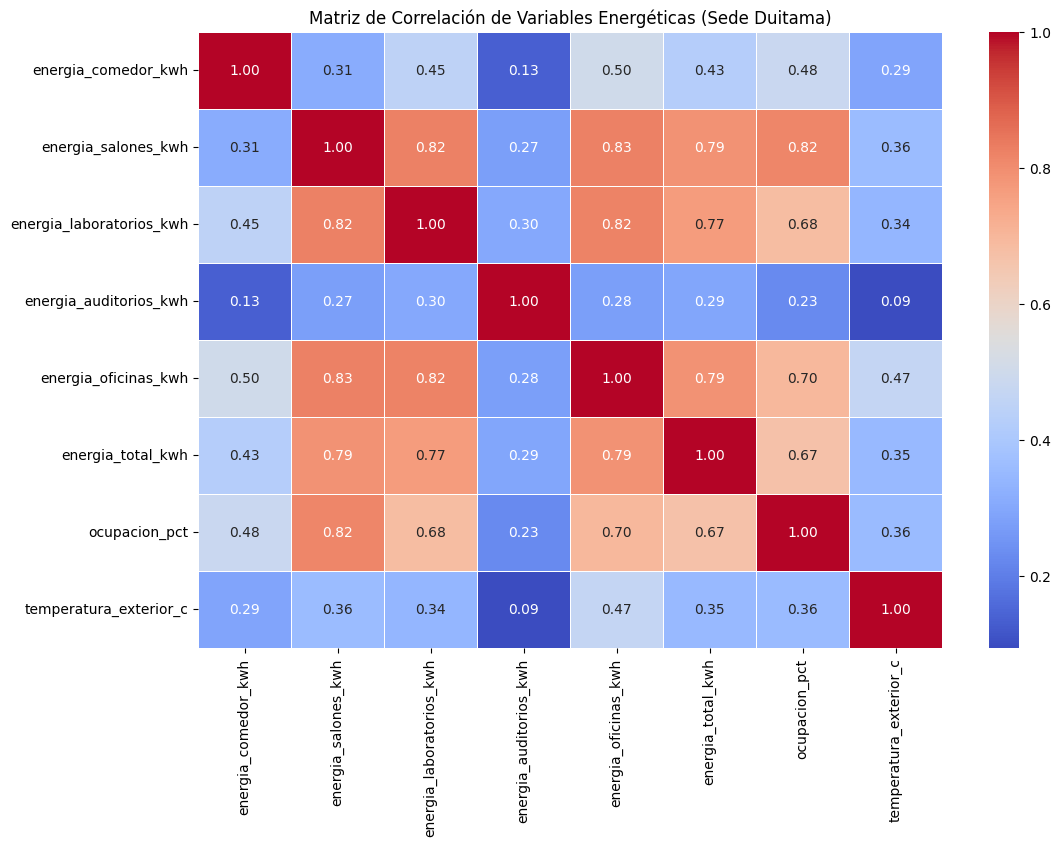

In [ ]:
# --- PASO 17: Matriz de correlación ---
plt.figure(figsize=(12, 8))

# Seleccionamos solo las variables numéricas para correlacionar
columnas_corr = columnas_energia_principales + ['energia_total_kwh', 'ocupacion_pct', 'temperatura_exterior_c']
matriz_corr = df_duitama[columnas_corr].corr()

# Graficamos el mapa de calor
sns.heatmap(matriz_corr, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Matriz de Correlación de Variables Energéticas (Sede Duitama)')
plt.show()

**Imputación y Correlación:**
- Para manejar los datos faltantes, se imputó la **mediana** en variables numéricas y la **moda** en categóricas, logrando **0 valores nulos**.
- La **matriz de correlación** revela relaciones muy fuertes (superiores a 0.80) entre el consumo de **salones, laboratorios y oficinas**. Esto sugiere que la actividad académica está altamente acoplada: un aumento en la ocupación de salones impacta directamente el consumo en laboratorios y oficinas.

In [ ]:
# --- PASO 18 y 19: Seleccionar variable objetivo (y) y predictoras (X) ---
# Vamos a predecir el consumo total de energía (energia_total_kwh)
# Basándonos en la matriz de correlación, las mejores variables para predecir son:
columnas_features = [
    'energia_salones_kwh',
    'energia_laboratorios_kwh',
    'energia_oficinas_kwh',
    'ocupacion_pct',
    'temperatura_exterior_c',
    'hora',
    'es_fin_semana',
    'es_festivo'
]

# Creamos el conjunto X (características) y Y (objetivo)
X = df_duitama[columnas_features]
y = df_duitama['energia_total_kwh']

print("Dimensiones de X (Predictoras):", X.shape)
print("Dimensiones de y (Objetivo):", y.shape)

Dimensiones de X (Predictoras): (57803, 8)
Dimensiones de y (Objetivo): (57803,)


In [ ]:
# --- PASO 20: Excluir variables no relevantes ---
# (En este caso, ya no las meti en X, así que no hay que hacer nada extra.
# Excluimos 'reading_id', 'timestamp' y 'sede', que no aportan a la predicción).

# --- PASO 21: Construir el conjunto final ---
# Unimos X y y en un solo DataFrame para dejarlo listo
dataset_final = pd.concat([X, y], axis=1)

print("\n¡Dataset final construido!")
print("Dimensiones del dataset final (filas, columnas):", dataset_final.shape)
display(dataset_final.head())


¡Dataset final construido!
Dimensiones del dataset final (filas, columnas): (57803, 9)


,energia_salones_kwh,energia_laboratorios_kwh,energia_oficinas_kwh,ocupacion_pct,temperatura_exterior_c,hora,es_fin_semana,es_festivo,energia_total_kwh
1,0.2007,1.7993,0.4217,4.1,10.9,0,False,True,2.592
5,0.2273,1.6791,0.4478,4.5,9.9,1,False,True,2.525
9,0.1993,1.8919,0.4193,4.1,8.0,2,False,True,2.685
13,0.1971,1.6748,0.4194,5.6,9.8,3,False,True,2.456
17,0.2000,1.7107,0.4616,4.7,10.5,4,False,True,2.551


In [ ]:
#dataset_final.to_csv('dataset_limpio_duitama.csv', index=False)
#print("\nArchivo 'dataset_limpio_duitama.csv' exportado con éxito.")

## Fase IV: Preparación para el Modelado Predictivo
**Construcción del conjunto final:**
Se seleccionó como **variable objetivo (y)** el consumo total de energía (`energia_total_kwh`). Para las **variables predictoras (X)**, se eligieron 8 características relevantes basadas en el análisis de correlación: consumos por sector, ocupación, temperatura, hora, fin de semana y festivos. Se excluyeron variables identificadoras (como `reading_id` y `timestamp`). El conjunto final resultante tiene **57,803 filas y 9 columnas**, listo para ser dividido en entrenamiento y prueba para modelos de IA.

# Conclusiones Finales

A partir del proceso de preparación de datos realizado sobre los consumos energéticos de la sede Duitama, se concluye lo siguiente:

1. **Calidad de los datos y depuración:** La base original presentaba deficiencias significativas (más del 10% de valores nulos en variables clave y datos físicamente imposibles como emisiones negativas de CO2). El proceso de imputación (mediana y moda) y la eliminación de registros inválidos garantizaron un conjunto de datos consistente y sin nulos, lo cual es fundamental para no sesgar los futuros modelos de IA.

2. **Patrones de consumo y comportamiento:** El análisis exploratorio demostró que el consumo en **laboratorios** es el más alto y variable (con picos de hasta 40 kWh), mientras que los auditorios presentan un consumo bajo y estable. Las distribuciones asimétricas evidencian que la universidad tiene picos de demanda puntuales, lo que sugiere oportunidades de optimización en horarios de uso.

3. **Relaciones entre sectores:** La matriz de correlación reveló una alta interdependencia entre los consumos de salones, laboratorios y oficinas (correlaciones superiores a 0.80), y una relación directa con el porcentaje de ocupación. Esto indica que el gasto energético de la sede no es aislado por sector, sino que responde a la dinámica global de la actividad académica.

4. **Valor para el modelado predictivo:** El conjunto de datos final (57,803 registros y 8 variables predictoras) está debidamente estructurado, libre de anomalías y con las características más relevantes seleccionadas. Este dataset es apto para entrenar modelos de regresión (como Random Forest o Regresión Lineal) que permitan predecir el consumo energético futuro y apoyar la toma de decisiones para la sostenibilidad institucional de la UPTC.